In [13]:
import re
import pandas as pd
from collections import defaultdict

# Function to extract data from the structure info file and group by space group
def extract_structure_data(file_path, functional_name, grouped_data):
    with open(file_path, 'r') as file:
        data = file.read()
    
    # Split data by separators
    phases = data.split('-----------------------------------------')
    
    for phase in phases:
        # Extract space group, lattice constants, and angles
        space_group_match = re.search(r'International:\s*(\S+)', phase)
        lattice_constants_match = re.search(r'Lattice Constants:\s*([\d\.]+\s+[\d\.]+\s+[\d\.]+)', phase)
        lattice_angles_match = re.search(r'Lattice Angles:\s*([\d\.]+\s+[\d\.]+\s+[\d\.]+)', phase)
        
        if space_group_match and lattice_constants_match and lattice_angles_match:
            space_group = space_group_match.group(1)
            lattice_constants = list(map(float, lattice_constants_match.group(1).split()))
            lattice_angles = list(map(float, lattice_angles_match.group(1).split()))
            
            # Store the data in the grouped_data dictionary
            if space_group not in grouped_data:
                grouped_data[space_group] = {'PBE': [], 'PBESol': [], 'HSE': []}
            
            # Store the lattice constants and angles in the corresponding functional category
            grouped_data[space_group][functional_name] = lattice_constants + lattice_angles

# Function to save the grouped data into a CSV file
def save_to_csv(file_paths, output_csv):
    grouped_data = defaultdict(lambda: {'PBE': [], 'PBESol': [], 'HSE': []})
    
    # Extract data from each file
    for file_path, functional_name in file_paths:
        extract_structure_data(file_path, functional_name, grouped_data)
    
    # Prepare the data for the CSV file
    all_data = []
    headers = ["Space Group", 
               "PBE a", "PBE b", "PBE c", "PBE alpha", "PBE beta", "PBE gamma", 
               "PBESol a", "PBESol b", "PBESol c", "PBESol alpha", "PBESol beta", "PBESol gamma", 
               "HSE a", "HSE b", "HSE c", "HSE alpha", "HSE beta", "HSE gamma"]
    
    # Organize data for each space group
    for space_group, data in grouped_data.items():
        row = [space_group]
        
        for functional in ['PBE', 'PBESol', 'HSE']:
            if data[functional]:
                row.extend(data[functional])
            else:
                # If no data for a particular functional, fill with NaN
                row.extend([float('nan')] * 6)  # 6 columns for lattice constants and angles
        
        all_data.append(row)
    
    # Save to CSV
    df = pd.DataFrame(all_data, columns=headers)
    df.to_csv(output_csv, index=False)






# File paths and corresponding functional names
file_paths = [
    ('HSE_structure_info.txt', 'HSE'),
    ('PBE_structure_info.txt', 'PBE'),
    ('PBESol_structure_info.txt', 'PBESol')
]

# Output CSV file
output_csv = 'structure_data_grouped_.csv'
save_to_csv(file_paths, output_csv)

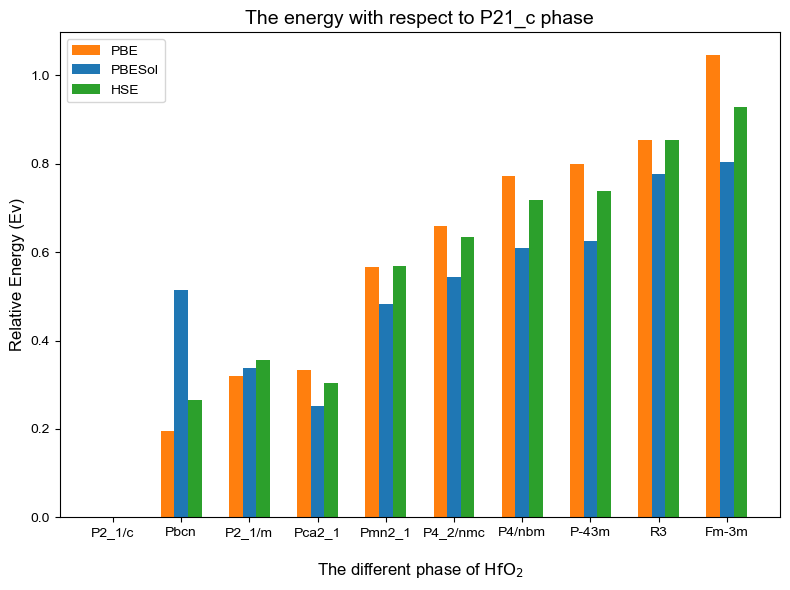

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib



matplotlib.rcParams['font.family'] = 'Arial'

def plot_comparison_bar_chart(csv_file):
    """
    This function reads a CSV file and plots a grouped bar chart comparing values
    from the second to fourth columns across different phases.
    
    Parameters:
    csv_file (str): Path to the input CSV file.
    """
    # Read the CSV file
    data = pd.read_csv(csv_file)
    
    # Extract data columns
    phases = data['phase']  # First column as phase labels
    pbe = data['PBE']  # Second column (PBE)
    pbesol = data['PBESol']  # Third column (PBESol)
    hse = data['HSE']  # Fourth column (HSE)
    
    # Set the position for each group of bars
    x = np.arange(len(phases))  # Position of each group of bars
    width = 0.2  # Width of each bar
    
    # Create a figure and axis for the plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot each set of bars with different colors
    ax.bar(x - width, pbe, width, label='PBE', color='tab:orange')
    ax.bar(x, pbesol, width, label='PBESol', color='tab:blue')
    ax.bar(x + width, hse, width, label='HSE', color='tab:green')
    
    # Set axis labels and title
    ax.set_xlabel(r'The different phase of $\text{HfO}_2$', fontsize=12, labelpad=15)
    ax.set_ylabel('Relative Energy (Ev)', fontsize=12)
    ax.set_title('The energy with respect to P21_c phase', fontsize=14)
    
    # Set x-axis ticks and labels (phase names)
    ax.set_xticks(x)
    ax.set_xticklabels(phases, rotation=0, ha='center')
    
    # Add legend to the plot
    # ax.legend(title="Functional", fontsize=10)
    ax.legend(fontsize=10)
    
    # Adjust layout to prevent clipping of labels
    plt.tight_layout()

    # save the plot
    plt.savefig('comparison_bar_chart_.png', dpi=600)
    
    # Show the plot
    plt.show()

# Example usage
csv_file = 'different_xc_energy_data.csv'  # Replace with your CSV file path
plot_comparison_bar_chart(csv_file)


In [20]:
import re
import pandas as pd
from collections import defaultdict

def extract_energy_data(file_path, functional_name, energy_data):
    with open(file_path, 'r') as file:
        data = file.read()
    
    # Split data by separators
    phases = data.split('-----------------------------------------')
    for phase in phases:
        space_group_match = re.search(r'International:\s*(\S+)', phase)
        energy_match = re.search(r"E0=\s*([-\d\.E+]+)", phase)

        if space_group_match and energy_match:
            space_group = space_group_match.group(1)
            energy = float(energy_match.group(1))

            if space_group not in energy_data:
                energy_data[space_group] = {'PBE': None, "PBE-ivdw": None}

            energy_data[space_group][functional_name] = energy

def save_energy_to_csv(file_paths, output_csv):
    energy_data = defaultdict(lambda: {'PBE': None, 'PBE-ivdw': None})

    # Extract data from each file
    for file_path, functional_name in file_paths:
        extract_energy_data(file_path, functional_name, energy_data)

    # Prepare the data for the CSV file
    all_data = []
    headers = ["Space Group", "PBE Energy (eV)", "PBE-ivdw Energy (eV)"]

    # Organize data for each space group
    for space_group, data in energy_data.items():
        row = [space_group, data['PBE'], data['PBE-ivdw']]
        all_data.append(row)

    df = pd.DataFrame(all_data, columns=headers)

    ## for PBE and PBE-ivdw, get the all phase energy with respect to P21_c phase
    for functional in ['PBE', 'PBE-ivdw']:
        p21_c_energy = df[df['Space Group'] == 'P2_1/c'][f"{functional} Energy (eV)"].values[0]
        df[f"{functional} Energy (eV)"] = df[f"{functional} Energy (eV)"] - p21_c_energy
        # convert to meV
        df[f"{functional} Energy (eV)"] = df[f"{functional} Energy (eV)"] * 1000/4

    # Save to CSV

    df = df.sort_values(by="PBE Energy (eV)")  # Sort by space group for better readability
    df.to_csv(output_csv, index=False)




file_paths = [("structure_info_pbe.txt", "PBE"),
              ("structure_info_pbe_ivdw.txt", "PBE-ivdw")
]
output_csv = 'pbe_and_pbe-ivdw_energy_data.csv'
save_energy_to_csv(file_paths, output_csv)


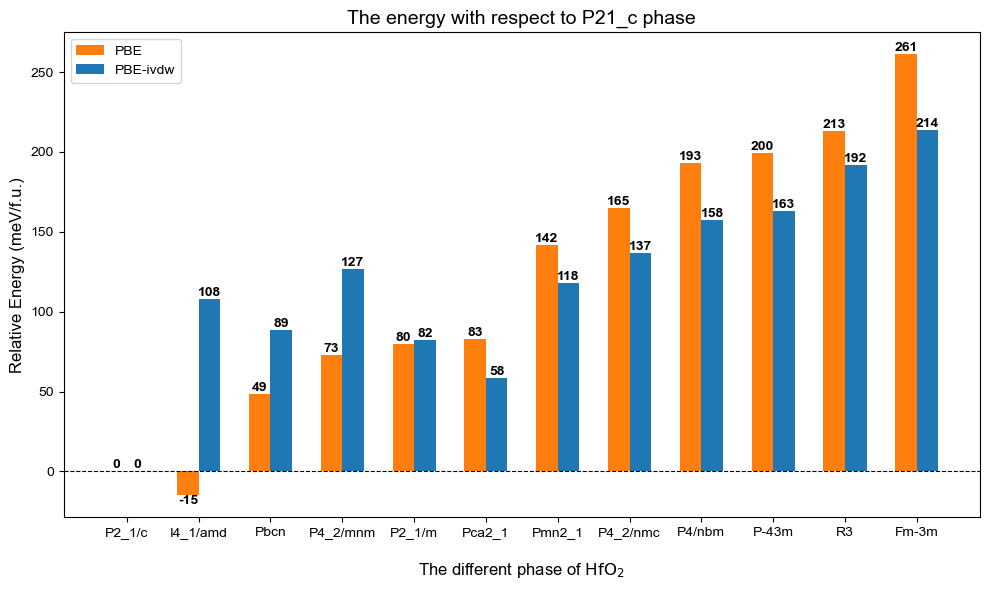

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib



matplotlib.rcParams['font.family'] = 'Arial'

def plot_comparison_bar_chart(csv_file):
    """
    This function reads a CSV file and plots a grouped bar chart comparing values
    from the second to fourth columns across different phases.
    
    Parameters:
    csv_file (str): Path to the input CSV file.
    """
    # Read the CSV file
    data = pd.read_csv(csv_file)
    
    # Extract data columns
    phases = data['Space Group']  # First column as phase labels
    pbe = data['PBE Energy (eV)'] # Second column (PBE)
    pbesol = data['PBE-ivdw Energy (eV)']
    
    # Set the position for each group of bars
    x = np.arange(len(phases))  # Position of each group of bars
    width = 0.3  # Width of each bar
    
    # Create a figure and axis for the plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot each set of bars with different colors
    bars1 = ax.bar(x - 0.5*width, pbe, width, label='PBE', color='tab:orange')
    bars2 = ax.bar(x + 0.5*width, pbesol, width, label='PBE-ivdw', color='tab:blue')

    def add_value_labels(bars):
        """
        Function to add value labels on top of the bars in a bar chart.
        
        Parameters:
        bars (list): List of bar containers returned by the bar plot function.
        """
        for bar in bars:
            height = bar.get_height()


            if height >= 0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height + 0.01,
                    f"{round(height)}",  # Format the height to two decimal places
                    ha='center', va='bottom', fontsize=10, color='black', rotation=0,
                    # set bold
                    fontweight='bold'
                )
            else:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height - 0.01,
                    f"{round(height)}",  # Format the height to two decimal places
                    ha='center', va='top', fontsize=10, color='black', rotation=0,
                    # set bold
                    fontweight='bold'
                )

    # Add value labels to the bars
    add_value_labels(bars1)
    add_value_labels(bars2)    

    
    # Set axis labels and title
    ax.set_xlabel(r'The different phase of $\text{HfO}_2$', fontsize=12, labelpad=15)
    ax.set_ylabel('Relative Energy (meV/f.u.)', fontsize=12)
    ax.set_title('The energy with respect to P21_c phase', fontsize=14)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')  # Add a horizontal line at y=0
    
    # Set x-axis ticks and labels (phase names)
    ax.set_xticks(x)
    ax.set_xticklabels(phases, rotation=0, ha='center')
    
    # Add legend to the plot
    # ax.legend(title="Functional", fontsize=10)
    ax.legend(fontsize=10)
    
    # Adjust layout to prevent clipping of labels
    plt.tight_layout()

    # save the plot
    plt.savefig('comparison_bar_chart.png', dpi=600)
    
    # Show the plot
    plt.show()

# Example usage
csv_file = 'pbe_and_pbe-ivdw_energy_data.csv'  # Replace with your CSV file path
plot_comparison_bar_chart(csv_file)

In [1]:
import re
import pandas as pd
from collections import defaultdict

def extract_energy_data(file_path, functional_name, energy_data):
    with open(file_path, 'r') as file:
        data = file.read()
    
    # Split data by separators
    phases = data.split('-----------------------------------------')
    for phase in phases:
        space_group_match = re.search(r'International:\s*(\S+)', phase)
        energy_match = re.search(r"E0=\s*([-\d\.E+]+)", phase)

        if space_group_match and energy_match:
            space_group = space_group_match.group(1)
            energy = float(energy_match.group(1))

            if space_group not in energy_data:
                energy_data[space_group] = {'PBE': None, "PBE-ivdw": None}

            energy_data[space_group][functional_name] = energy

def save_energy_to_csv(file_paths, output_csv):
    energy_data = defaultdict(lambda: {'PBE': None, 'PBE-ivdw': None})

    # Extract data from each file
    for file_path, functional_name in file_paths:
        extract_energy_data(file_path, functional_name, energy_data)

    # Prepare the data for the CSV file
    all_data = []
    headers = ["Space Group", "PBE Energy (eV)", "PBE-ivdw Energy (eV)"]

    # Organize data for each space group
    for space_group, data in energy_data.items():
        row = [space_group, data['PBE'], data['PBE-ivdw']]
        all_data.append(row)

    df = pd.DataFrame(all_data, columns=headers)

    ## for PBE and PBE-ivdw, get the all phase energy with respect to P21_c phase
    for functional in ['PBE', 'PBE-ivdw']:
        p21_c_energy = df[df['Space Group'] == 'Fm-3m'][f"{functional} Energy (eV)"].values[0]
        df[f"{functional} Energy (eV)"] = df[f"{functional} Energy (eV)"] - p21_c_energy
        # convert to meV
        df[f"{functional} Energy (eV)"] = df[f"{functional} Energy (eV)"] * 1000/4

    # Save to CSV

    df = df.sort_values(by="PBE Energy (eV)")  # Sort by space group for better readability
    df.to_csv(output_csv, index=False)




file_paths = [("structure_info_pbe.txt", "PBE"),
              ("structure_info_pbe_ivdw.txt", "PBE-ivdw")
]
output_csv = 'pbe_and_pbe-ivdw_energy_data_with_respect_to_fm-3m.csv'
save_energy_to_csv(file_paths, output_csv)


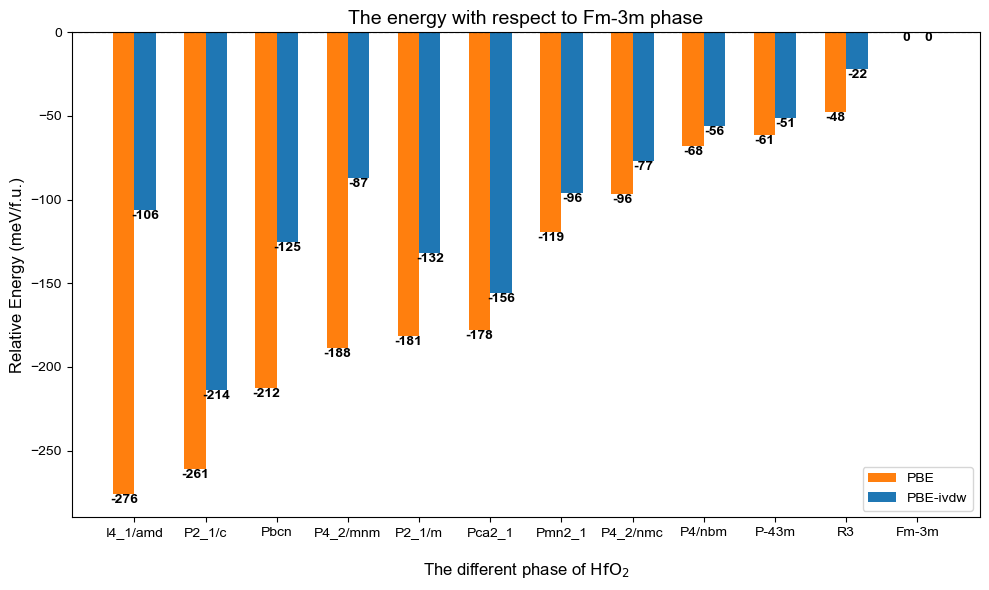

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib



matplotlib.rcParams['font.family'] = 'Arial'

def plot_comparison_bar_chart(csv_file):
    """
    This function reads a CSV file and plots a grouped bar chart comparing values
    from the second to fourth columns across different phases.
    
    Parameters:
    csv_file (str): Path to the input CSV file.
    """
    # Read the CSV file
    data = pd.read_csv(csv_file)
    
    # Extract data columns
    phases = data['Space Group']  # First column as phase labels
    pbe = data['PBE Energy (eV)'] # Second column (PBE)
    pbesol = data['PBE-ivdw Energy (eV)']
    
    # Set the position for each group of bars
    x = np.arange(len(phases))  # Position of each group of bars
    width = 0.3  # Width of each bar
    
    # Create a figure and axis for the plot
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Plot each set of bars with different colors
    bars1 = ax.bar(x - 0.5*width, pbe, width, label='PBE', color='tab:orange')
    bars2 = ax.bar(x + 0.5*width, pbesol, width, label='PBE-ivdw', color='tab:blue')

    def add_value_labels(bars):
        """
        Function to add value labels on top of the bars in a bar chart.
        
        Parameters:
        bars (list): List of bar containers returned by the bar plot function.
        """
        for bar in bars:
            height = bar.get_height()


            if height >= 0:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height + 0.01,
                    f"{round(height)}",  # Format the height to two decimal places
                    ha='center', va='bottom', fontsize=10, color='black', rotation=0,
                    # set bold
                    fontweight='bold'
                )
            else:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    height - 0.01,
                    f"{round(height)}",  # Format the height to two decimal places
                    ha='center', va='top', fontsize=10, color='black', rotation=0,
                    # set bold
                    fontweight='bold'
                )

    # Add value labels to the bars
    add_value_labels(bars1)
    add_value_labels(bars2)    

    
    # Set axis labels and title
    ax.set_xlabel(r'The different phase of $\text{HfO}_2$', fontsize=12, labelpad=15)
    ax.set_ylabel('Relative Energy (meV/f.u.)', fontsize=12)
    ax.set_title('The energy with respect to Fm-3m phase', fontsize=14)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')  # Add a horizontal line at y=0
    
    # Set x-axis ticks and labels (phase names)
    ax.set_xticks(x)
    ax.set_xticklabels(phases, rotation=0, ha='center')
    
    # Add legend to the plot
    # ax.legend(title="Functional", fontsize=10)
    ax.legend(fontsize=10)
    
    # Adjust layout to prevent clipping of labels
    plt.tight_layout()

    # save the plot
    plt.savefig('comparison_bar_chart.png', dpi=600)
    
    # Show the plot
    plt.show()

# Example usage
csv_file = 'pbe_and_pbe-ivdw_energy_data_with_respect_to_fm-3m.csv'  # Replace with your CSV file path
plot_comparison_bar_chart(csv_file)